# Multiple examples on how to use the visualization tools provided by pyRadPlan.

This example demonstrates the usage of `plot_slice()` and `plot_multiple_slices()`.

To display this script in a Jupyter Notebook, you need to install jupytext via pip and run the following command.
This will create a .ipynb file in the same directory:

```bash
pip install jupytext
jupytext --to notebook path/to/this/file/utils_plotting.py

In [1]:
# Import necessary libraries
import logging

import matplotlib.pyplot as plt

from pyRadPlan import (
    IonPlan,
    generate_stf,
    calc_dose_influence,
    fluence_optimization,
    plot_slice,
    plot_multiple_slices,
    load_tg119,
)

logging.basicConfig(level=logging.INFO)

### Just like in other examples, we need to generate some distributions/quantities to visualize.

In [2]:
# load TG119
ct, cst = load_tg119()

# Create a plan object
pln = IonPlan(radiation_mode="carbon", machine="Generic")
pln.prop_opt = {"solver": "scipy"}
# The default carbon bio_model (alpha_beta_kernels) computes the biological dose

# Generate Steering Geometry ("stf")
stf = generate_stf(ct, cst, pln)

# Calculate Dose Influence Matrix ("dij")
dij = calc_dose_influence(ct, cst, stf, pln)

# Run fluence optimization and compute the result
fluence = fluence_optimization(ct, cst, stf, dij, pln)
result = dij.compute_result_ct_grid(fluence)

### Visualizing a single slice with `plot_slice()`

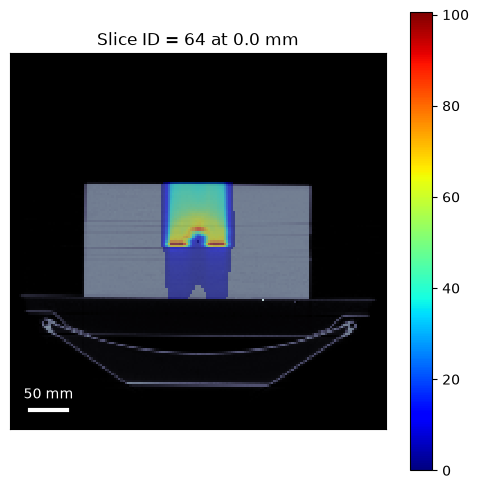

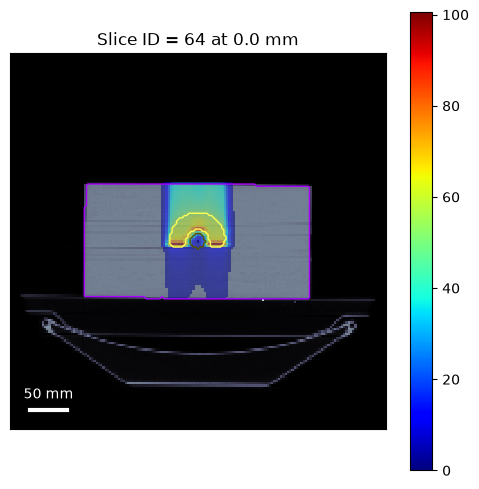

In [3]:

# Visualize only ct and chosen quantity
plot_slice(image_volume=ct, overlay=result["physical_dose"])

# Visualize ct, cst and chosen quantity
plot_slice(image_volume=ct, cst=cst, overlay=result["physical_dose"])

## Visualze more abstract settings using `plot_slice()` <br>

`plot_slice()` has multiple tweakable parameters:
- **image_volume**: The CT data to visualize
- **cst**: The structure set to visualize (optional)
- **overlay**: The quantity to visualize
- **view_slice**: Which slice to visualize (default: middle slice)
- **plane**: Which plane to visualize (default: "axial")
- **overlay_alpha**: Transparency of the overlay (default: 0.5)
- **overlay_rel_threshold**: Relative threshold for the overlay (default: 0.01)
- **overlay_unit**: The unit of the overlay quantity (default: "Gy")
- **save_filename**: If provided, saves the plot to a file
- **show_plot**: Whether to show the plot (default: True)
- **use_global_max**: If True, uses the global maximum of the overlay for scaling (default: False)
- **ax**: If provided, plots on the given axes (useful for subplots) - use of 'plot_multiple_slices()' is recommended

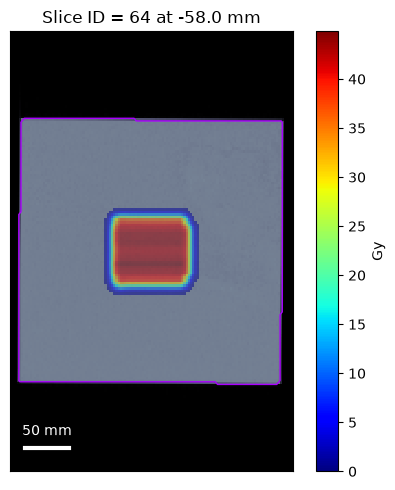

In [4]:
# Feel free to change the parameters to see how they affect the plot.
plot_slice(
    image_volume=ct,
    cst=cst,
    overlay=result["physical_dose"],
    view_slice=64,  # Visualize slice 64
    plane="coronal",  # axial, coronal or sagittal
    overlay_alpha=0.5,  # Transparency of the overlay
    overlay_unit="Gy",  # Gy, dimensionless, etc.
    overlay_rel_threshold=0.01,  # Relative threshold for the overlay
    contour_line_width=1.0,  # Width of the contour lines
    save_filename=None,  # alt: path/to/save/plot.png
    show_plot=True,  # Show the plot
    use_global_max=False,  # Do not use global max for scaling
)

### Visualizing multiple overlays/quantities with `plot_multiple_slices()`
This function might be useful in cases you want to compare multiple overlays/quantities/beams side by side.

`plot_multiple_slices()` has similar parameters to `plot_slice()`:
- **image_volume**:  The CT data to visualize
- **cst**:  The structure set to visualize (optional)
- **overlays**:  List of overlay images to visualize
- **view_slice**:  Which slices to visualize (default: middle slice)
- **plane**:  Which plane to visualize (default: "axial")
- **overlay_alpha**:  Transparency of the overlay (default: 0.5)
- **overlay_unit**:  List of units for each overlay (default: "Gy")
- **overlay_rel_threshold**:  Relative threshold for the overlay (default: 0.01)
- **contour_line_width**:  Line width for the contour lines (default: 1.0)
- **save_filename**:  If provided, saves the plot to a file
- **show_plot**:  Whether to show the plot (default: True)
- **use_global_max**:  If True, uses the global maximum of the overlay for scaling
- **overlay_titles**:  Custom titles for each overlay type (optional)

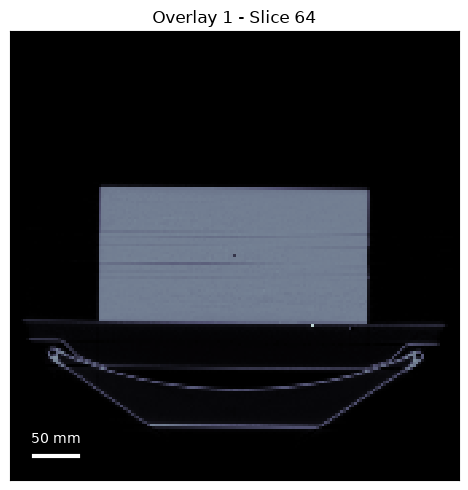

In [5]:
plot_multiple_slices(
    image_volume=ct,
)

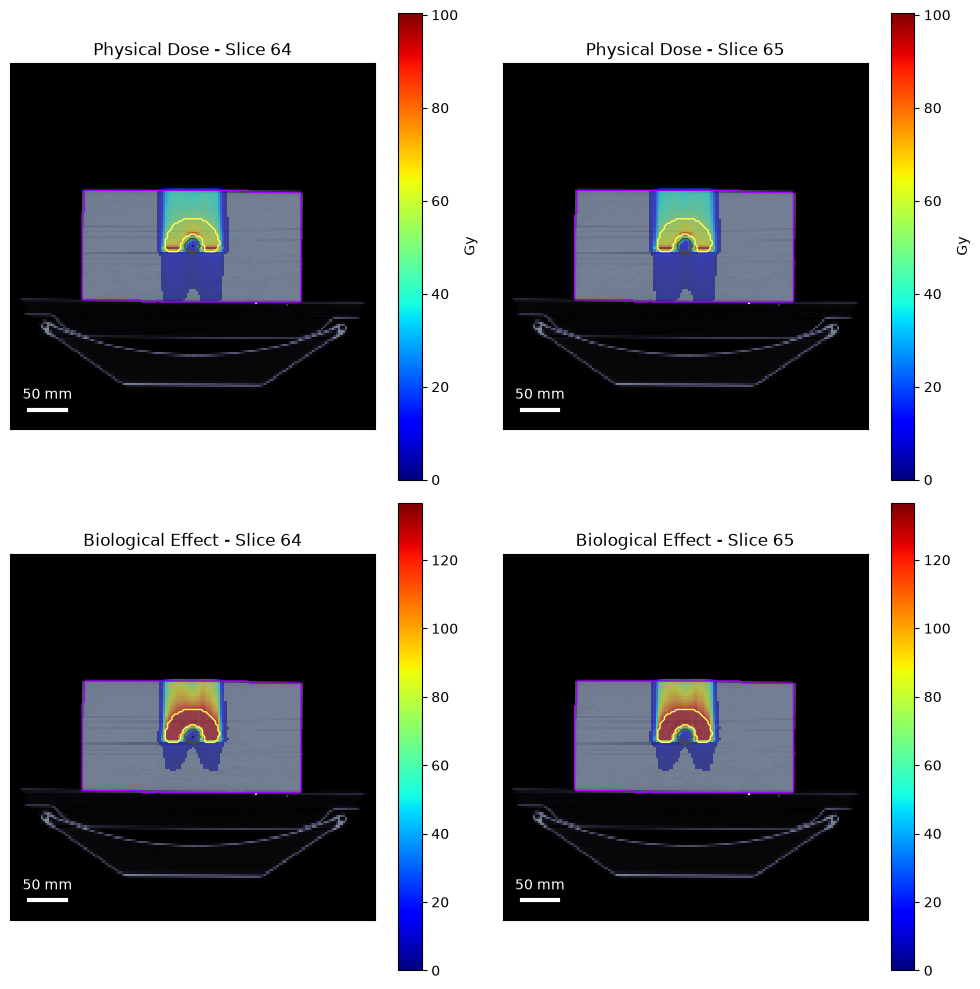

In [6]:
# Feel free to change the parameters to see how they affect the plot.
plot_multiple_slices(
    image_volume=ct,
    cst=cst,
    overlays=[result["physical_dose"], result["effect"]],
    view_slice=[64, 65],  # Visualize slices 64 and 65
    plane="axial",  # axial, coronal or sagittal
    overlay_alpha=0.5,  # Transparency of the overlay
    overlay_unit=["Gy", "dimensionless"],  # Units for each overlay
    overlay_rel_threshold=0.01,  # Relative threshold for the overlay
    contour_line_width=1.0,  # Width of the contour lines
    save_filename=None,  # alt: path/to/save/plot.png
    show_plot=True,  # Show the plot
    use_global_max=False,  # Do not use global max for scaling
    overlay_titles=["Physical Dose", "Biological Effect"],  # Titles for each overlay
)

### Being more flexible with only `plot_slice()` is also possible:

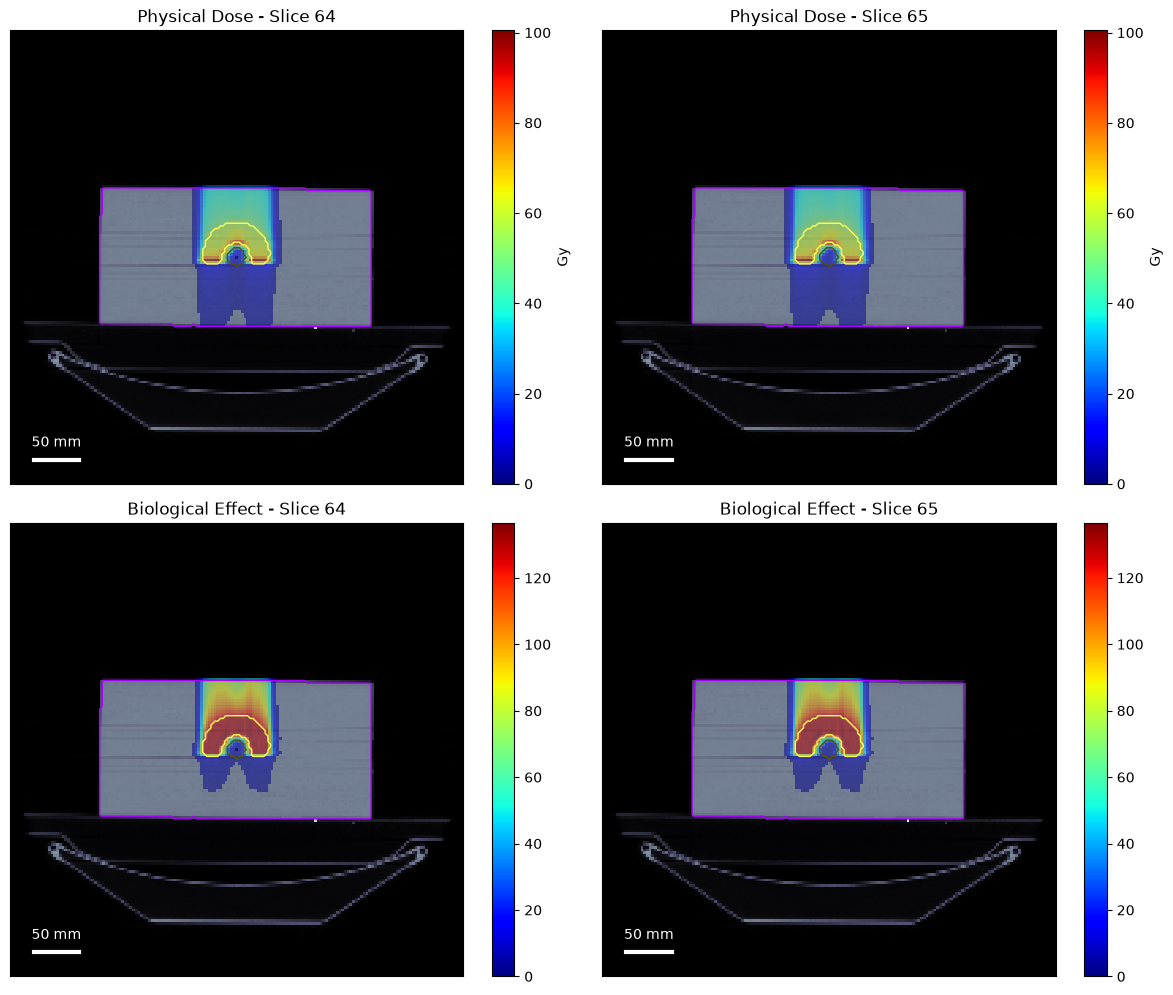

In [7]:
# Create a figure with subplots for side-by-side comparison
# 2 rows (physical dose, biological effect) x 2 cols (slice1, slice2)
slices = [64, 65]  # Slices to visualize
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Plot physical dose for both slices
for i, slice_idx in enumerate(slices):
    plot_slice(
        image_volume=ct,
        cst=cst,
        overlay=result["physical_dose"],
        view_slice=slice_idx,  # Single slice
        plane="axial",
        overlay_unit="Gy",
        show_plot=False,
        ax=axes[0, i],  # Top row
    )
    axes[0, i].set_title(f"Physical Dose - Slice {slice_idx}")

# Plot biological effect for both slices
for i, slice_idx in enumerate(slices):
    plot_slice(
        image_volume=ct,
        cst=cst,
        overlay=result["effect"],
        view_slice=slice_idx,  # Single slice
        plane="axial",
        overlay_unit="dimensionless",
        show_plot=False,
        ax=axes[1, i],  # Bottom row
    )
    axes[1, i].set_title(f"Biological Effect - Slice {slice_idx}")

plt.tight_layout()
plt.show()